In [1]:
# Day - 01 (Import and load the data).

In [2]:
import pandas as pd
from pathlib import Path

#Get all CSV files from the folder.
data_dir = Path("../data/raw")
files = sorted(data_dir.glob("*.csv"))
print(f"Files found: {len(files)}\n")

Files found: 10



In [3]:
#Loop through all the files.
for file in files:
    df = pd.read_csv(file)
    print(file.name)
    print("rows:", len(df))
    print("columns:", list(df.columns))
    print("first:", df.iloc[0,0], "| last:", df.iloc[-1,0])
    print("datatypes:", dict(df.dtypes.astype(str)))
    print()

NIFTY 50-01-01-2016-to-31-12-2016.csv
rows: 247
columns: ['Date ', 'Open ', 'High ', 'Low ', 'Close ', 'Shares Traded ', 'Turnover (₹ Cr)']
first: 30-DEC-2016 | last: 01-JAN-2016
datatypes: {'Date ': 'str', 'Open ': 'float64', 'High ': 'float64', 'Low ': 'float64', 'Close ': 'float64', 'Shares Traded ': 'int64', 'Turnover (₹ Cr)': 'float64'}

NIFTY 50-01-01-2017-to-31-12-2017.csv
rows: 248
columns: ['Date ', 'Open ', 'High ', 'Low ', 'Close ', 'Shares Traded ', 'Turnover (₹ Cr)']
first: 29-DEC-2017 | last: 02-JAN-2017
datatypes: {'Date ': 'str', 'Open ': 'float64', 'High ': 'float64', 'Low ': 'float64', 'Close ': 'float64', 'Shares Traded ': 'int64', 'Turnover (₹ Cr)': 'float64'}

NIFTY 50-01-01-2018-to-31-12-2018.csv
rows: 246
columns: ['Date ', 'Open ', 'High ', 'Low ', 'Close ', 'Shares Traded ', 'Turnover (₹ Cr)']
first: 31-DEC-2018 | last: 01-JAN-2018
datatypes: {'Date ': 'str', 'Open ': 'float64', 'High ': 'float64', 'Low ': 'float64', 'Close ': 'float64', 'Shares Traded ': 'int6

In [4]:
#Merge the files.
frames = []
for file in files:
    df = pd.read_csv(file)
    df.columns = df.columns.str.strip()
    assert len(df.columns) == 7, f"Unexpected columns in {file.name}"
    df.columns = ["date", "open", "high", "low", "close", "shares_traded", "turnover_cr"]
    df["source_file"] = file.name
    frames.append(df)

nifty = pd.concat(frames, ignore_index = True)

#Parse dates like 30-DEC-2025
nifty["date"] = pd.to_datetime(nifty["date"], format = "%d-%b-%Y")

#Oldest to newest
nifty = nifty.sort_values("date").reset_index(drop = True)

print(nifty.shape)
print(nifty["date"].min(), "->", nifty["date"].max())
print(nifty.head())
print(nifty.tail())

(2477, 8)
2016-01-01 00:00:00 -> 2025-12-31 00:00:00
        date     open     high      low    close  shares_traded  turnover_cr  \
0 2016-01-01  7938.45  7972.55  7909.80  7963.20       64843836      2613.91   
1 2016-01-04  7924.55  7937.55  7781.10  7791.30      138864905      5897.08   
2 2016-01-05  7828.40  7831.20  7763.25  7784.65      149672973      5948.51   
3 2016-01-06  7788.05  7800.95  7721.20  7741.00      151715828      6722.17   
4 2016-01-07  7673.35  7674.95  7556.60  7568.30      194732861      7803.21   

                             source_file  
0  NIFTY 50-01-01-2016-to-31-12-2016.csv  
1  NIFTY 50-01-01-2016-to-31-12-2016.csv  
2  NIFTY 50-01-01-2016-to-31-12-2016.csv  
3  NIFTY 50-01-01-2016-to-31-12-2016.csv  
4  NIFTY 50-01-01-2016-to-31-12-2016.csv  
           date      open      high      low     close  shares_traded  \
2472 2025-12-24  26170.65  26236.40  26123.0  26142.10      188846828   
2473 2025-12-26  26121.25  26144.20  26008.6  26042.30      14

In [5]:
#Check the loaded data.
print("Rows:", len(nifty))
print("Unparsed dates:", nifty["date"].isna().sum())
print("Duplicate dates:", nifty["date"].duplicated().sum())
print(nifty.groupby(nifty["date"].dt.year).size())
print("Dates strictly increasing:", nifty["date"].is_monotonic_increasing)

Rows: 2477
Unparsed dates: 0
Duplicate dates: 0
date
2016    247
2017    248
2018    246
2019    245
2020    252
2021    248
2022    248
2023    246
2024    248
2025    249
dtype: int64
Dates strictly increasing: True


In [6]:
#Save the merged file.
nifty.to_csv("Nifty_10y_raw.csv", index = False)

In [7]:
# Day - 02 (Clean and Validate).

In [8]:
#Nulls and datatypes.
print(nifty.isna().sum())
print(nifty.dtypes)
print(nifty.describe().T)

date             0
open             0
high             0
low              0
close            0
shares_traded    0
turnover_cr      0
source_file      0
dtype: int64
date             datetime64[us]
open                    float64
high                    float64
low                     float64
close                   float64
shares_traded             int64
turnover_cr             float64
source_file                 str
dtype: object
                count                        mean                  min  \
date             2477  2021-01-01 19:25:01.332256  2016-01-01 00:00:00   
open           2477.0                15140.053048              7023.65   
high           2477.0                15208.264009               7034.2   
low            2477.0                15050.333569               6825.8   
close          2477.0                15131.149919               6970.6   
shares_traded  2477.0            342546458.211143           16610872.0   
turnover_cr    2477.0                21811.4027

In [9]:
#Non-Positive or zero values.
print("Non-Positive or zero values:", (nifty[['open', 'high', 'low', 'close']] <= 0).sum().sum())
print("Zero/negative shares:", (nifty['shares_traded'] <= 0).sum())
print("Zero/negative turnover:", (nifty['turnover_cr'] <= 0).sum())

Non-Positive or zero values: 0
Zero/negative shares: 0
Zero/negative turnover: 0


In [10]:
#OLHC logic check.
bad_high = nifty['high'] < nifty[['open', 'low', 'close']].max(axis = 1)
bad_low = nifty['low'] > nifty[['open', 'high', 'close']].min(axis = 1)
print("High below another price:", bad_high.sum())
print("Low above another price:", bad_low.sum())
print(nifty[bad_high | bad_low])

High below another price: 0
Low above another price: 0
Empty DataFrame
Columns: [date, open, high, low, close, shares_traded, turnover_cr, source_file]
Index: []


In [11]:
#Weekend rows check.
weekend = nifty[nifty['date'].dt.dayofweek >= 5]
print(len(weekend))
print(weekend[['open', 'close', 'shares_traded']])

8
          open     close  shares_traded
203    8672.35   8625.70       16610872
941   11662.25  11627.15      161779004
1009  11939.00  11661.85      537634767
1206  12823.35  12780.25      107868139
1947  19547.25  19525.55       37311902
1995  21706.15  21571.80      162073740
2073  22512.85  22502.00       19064566
2251  23528.60  23482.15      287703637


In [12]:
#Gap in the calender.
gap = nifty['date'].diff().dt.days
print(gap.value_counts().sort_index())
print(nifty.loc[gap >= 5, 'date'])

date
1.0    1881
2.0      77
3.0     459
4.0      55
5.0       4
Name: count, dtype: int64
57     2016-03-28
70     2016-04-18
555    2018-04-02
1556   2022-04-18
Name: date, dtype: datetime64[us]


In [13]:
#Extreme daily moves.
ret = nifty['close'].pct_change()
print(ret.describe())
print(nifty.loc[ret.abs() > 0.05, ['date', 'close']].assign(ret = ret[ret.abs() > 0.05]))

count    2476.000000
mean        0.000533
std         0.010209
min        -0.129805
25%        -0.004155
50%         0.000693
75%         0.005757
max         0.087632
Name: close, dtype: float64
           date     close       ret
918  2019-09-20  11274.20  0.053191
1036 2020-03-12   9590.15 -0.083019
1038 2020-03-16   9197.40 -0.076121
1040 2020-03-18   8468.80 -0.055565
1042 2020-03-20   8745.45  0.058329
1043 2020-03-23   7610.25 -0.129805
1045 2020-03-25   8317.85  0.066247
1052 2020-04-07   8792.20  0.087632
1068 2020-05-04   9293.50 -0.057445
2084 2024-06-04  21884.50 -0.059294


In [14]:
#The 8 weekend rows and the volume extremes.
cols = ['date', 'close', 'shares_traded', 'turnover_cr']

#Weekend rows with dates.
w = nifty[nifty['date'].dt.dayofweek >= 5]
print(w[cols].assign(day = w['date'].dt.day_name()))
print()

#15 lowest-volume days.
low = nifty.nsmallest(15, 'shares_traded')
print(low[cols].assign(day = low['date'].dt.day_name()))
print()

#10 highest-volume days.
high = nifty.nlargest(10, 'shares_traded')
print(high[cols].assign(day = high['date'].dt.day_name()))
print()

#Cross-check (implied average traded price per share).
avg_price = nifty['turnover_cr'] * 1e7 / nifty['shares_traded']
print(avg_price.describe())

           date     close  shares_traded  turnover_cr       day
203  2016-10-30   8625.70       16610872       805.89    Sunday
941  2019-10-27  11627.15      161779004      3548.21    Sunday
1009 2020-02-01  11661.85      537634767     20598.12  Saturday
1206 2020-11-14  12780.25      107868139      5189.38  Saturday
1947 2023-11-12  19525.55       37311902      2482.27    Sunday
1995 2024-01-20  21571.80      162073740     13917.46  Saturday
2073 2024-05-18  22502.00       19064566      1572.77  Saturday
2251 2025-02-01  23482.15      287703637     25741.04  Saturday

           date     close  shares_traded  turnover_cr        day
203  2016-10-30   8625.70       16610872       805.89     Sunday
2073 2024-05-18  22502.00       19064566      1572.77   Saturday
445  2017-10-19  10146.55       31086379      1685.16   Thursday
705  2018-11-07  10598.40       32194181      1534.08  Wednesday
1947 2023-11-12  19525.55       37311902      2482.27     Sunday
2188 2024-11-01  24304.35       3

In [15]:
#Neighbours of 10 JUL 2017.
i = nifty.index[nifty['date'] == '2017-07-10'][0]
print(nifty.loc[i-4:i+4, cols])

#Highest turnover days.
print(nifty.nlargest(5, 'turnover_cr')[cols])

#Implied price per share, median by year.
print(avg_price.groupby(nifty['date'].dt.year).median().round(0))

          date    close  shares_traded  turnover_cr
371 2017-07-04  9613.30      149313755      7774.69
372 2017-07-05  9637.60      134849476      7311.10
373 2017-07-06  9674.55      152001940      7539.21
374 2017-07-07  9665.80      146232151      8514.53
375 2017-07-10  9771.05       40142973      1920.78
376 2017-07-11  9786.05      185322358      9908.41
377 2017-07-12  9816.10      150045594      7966.44
378 2017-07-13  9891.70      186866752     10244.56
379 2017-07-14  9886.35      164456602      9187.71
           date     close  shares_traded  turnover_cr
2084 2024-06-04  21884.50     1006105058     93786.44
2144 2024-08-30  25235.90      638166179     89554.91
2202 2024-11-25  24221.90      687172787     85975.81
1215 2020-11-27  12968.95     1162360673     78522.93
1834 2023-05-31  18534.40      696495765     70755.08
date
2016     436.0
2017     516.0
2018     534.0
2019     431.0
2020     476.0
2021     721.0
2022     807.0
2023     905.0
2024    1024.0
2025     912.0
d

In [16]:
'''
Validate first. Then set aside the 12 short sessions (10 Diwali Muhurat sessions and 2 special Saturday sessions). 
They last about an hour, so their volume would look like a false collapse. The two Budget-day Saturdays were full sessions and stay in.
'''
short_dates = pd.to_datetime([
    #Diwali Muhurat sessions (about 1 hour)
    '2016-10-30', '2017-10-19', '2018-11-07', '2019-10-27', '2020-11-14',
    '2021-11-04', '2022-10-24', '2023-11-12', '2024-11-01', '2025-10-21',
    #Special saturday sessions (disaster - recovery site tests)
    '2024-01-20', '2024-05-18',
])

nifty['short_session'] = nifty['date'].isin(short_dates)
assert nifty['short_session'].sum() == 12

excluded = nifty[nifty['short_session']]
nifty_clean = (nifty[~nifty['short_session']]
               .drop(columns = ['short_session', 'source_file'])
               .reset_index(drop = True))

print(len(nifty), '->', len(nifty_clean))

#Re-check: only the two budget saturdays should remain.
print(nifty_clean[nifty_clean['date'].dt.dayofweek >= 5][cols])

#Lowest volumes now.
print(nifty_clean.nsmallest(5, 'shares_traded')[cols])

nifty_clean.to_csv('Nifty_10y_clean.csv', index = False)
excluded.to_csv('Nifty_10y_excluded_sessions.csv', index = False)

2477 -> 2465
           date     close  shares_traded  turnover_cr
1005 2020-02-01  11661.85      537634767     20598.12
2240 2025-02-01  23482.15      287703637     25741.04
          date    close  shares_traded  turnover_cr
374 2017-07-10  9771.05       40142973      1920.78
0   2016-01-01  7963.20       64843836      2613.91
251 2017-01-09  8236.05      102211190      5197.62
241 2016-12-26  7908.25      110171222      4808.67
236 2016-12-19  8104.35      110669713      5272.20


In [17]:
# Day - 03 (Calculate returns - daily and log returns respectively).

In [18]:
import numpy as np

df = pd.read_csv("Nifty_10y_clean.csv", parse_dates = ['date'])

df['ret'] = df['close'].pct_change()
df['log_ret'] = np.log(df['close'] / df['close'].shift(1))

print(df['log_ret'].isna().sum())
print(df['log_ret'].describe(), '\n')

#Log return should equal to (1 + simple return).
print("Log/simple_return:", np.allclose(df['log_ret'], np.log1p(df['ret']), equal_nan = True), '\n')

#Compounding check.
print((1 + df['ret']).prod() - 1)
print(df['close'].iloc[-1] / df['close'].iloc[0] - 1, '\n')

#Biggest moves.
print(df.nsmallest(5, 'ret')[['date', 'close', 'ret']])
print(df.nlargest(5, 'ret')[['date', 'close', 'ret']])

1
count    2464.000000
mean        0.000482
std         0.010296
min        -0.139038
25%        -0.004164
50%         0.000687
75%         0.005762
max         0.084003
Name: log_ret, dtype: float64 

Log/simple_return: True 

2.2812939521800377
2.281293952180028 

           date     close       ret
1039 2020-03-23   7610.25 -0.129805
1032 2020-03-12   9590.15 -0.083019
1034 2020-03-16   9197.40 -0.076121
2074 2024-06-04  21884.50 -0.059294
1064 2020-05-04   9293.50 -0.057445
           date     close       ret
1048 2020-04-07   8792.20  0.087632
1041 2020-03-25   8317.85  0.066247
1038 2020-03-20   8745.45  0.058329
915  2019-09-20  11274.20  0.053191
1253 2021-02-01  14281.20  0.047423


In [19]:
# Day - 04 (Rolling Volatility for 30D, 60D and 90D).

In [20]:
#Calculating rolling volatility for 30D, 60D and 90D.
TRADING_DAYS = 252

for w in [30, 60, 90]:
    df[f'vol_{w}'] = (df['log_ret'].rolling(window = w, min_periods = w).std()
                      * np.sqrt(TRADING_DAYS))

vol_cols = ['vol_30', 'vol_60', 'vol_90']
print(df[vol_cols].isna().sum())
print(df[vol_cols].describe(), '\n')

#Manual check of one value (30-day window ending at 100)
i = 100
manual = df['log_ret'].iloc[i - 29: i + 1].std() * np.sqrt(TRADING_DAYS)
print('Manual match:', np.isclose(df.loc[i, 'vol_30'], manual), '\n')

#When was volatility highest, and what is the typical level by year?
print(df.loc[df['vol_30'].idxmax(), ['date', 'vol_30']], '\n')
print(df.groupby(df['date'].dt.year)[vol_cols].mean().round(3))


vol_30    30
vol_60    60
vol_90    90
dtype: int64
            vol_30       vol_60       vol_90
count  2435.000000  2405.000000  2375.000000
mean      0.140903     0.144175     0.146744
std       0.082792     0.077294     0.073191
min       0.061786     0.074686     0.076434
25%       0.096556     0.101698     0.107905
50%       0.120787     0.126602     0.130838
75%       0.158762     0.164105     0.161833
max       0.765551     0.586345     0.489988 

Manual match: True 

date      2020-04-23 00:00:00
vol_30               0.765551
Name: 1058, dtype: object 

      vol_30  vol_60  vol_90
date                        
2016   0.147   0.140   0.137
2017   0.093   0.097   0.100
2018   0.120   0.119   0.115
2019   0.135   0.142   0.143
2020   0.252   0.264   0.278
2021   0.148   0.148   0.152
2022   0.169   0.176   0.176
2023   0.096   0.097   0.100
2024   0.134   0.136   0.136
2025   0.114   0.119   0.123


In [21]:
# Day - 05 (Drawdown for 30D, 60D and 90D).

In [22]:
#Drawdown from the highest close so far.
df['peak'] = df['close'].cummax()
df['dd_all'] = df['close'] / df['peak'] - 1

#Max drawdown inside each rolling window.
def max_dd(x):
    return (x / np.maximum.accumulate(x) - 1).min()

for w in [30, 60, 90]:
    df[f'mdd_{w}'] = (df['close'].rolling(window = w, min_periods = w).apply(max_dd, raw = True))

mdd_cols = ['mdd_30', 'mdd_60', 'mdd_90']

print(df[['dd_all'] + mdd_cols].isna().sum())
print(df[['dd_all'] + mdd_cols].describe(), '\n')

#Independent check: a longer window contains the shorter one, so its max drawdown can never be smaller.
valid = df[mdd_cols].dropna()
print('Nestes check:', ((valid['mdd_90'] <= valid['mdd_60']) &
                        (valid['mdd_60'] <= valid['mdd_30'])).all(), '\n')

#Known event: The COVID crash.
print(df.loc[df['date'] == '2020-03-23', ['close', 'peak', 'dd_all'] + mdd_cols], '\n')

#Deepest drawdown and worst drawdown per year.
print(df.loc[df['dd_all'].idxmin(), ['date', 'close', 'peak', 'dd_all']])
print(df.groupby(df['date'].dt.year)['dd_all'].min().round(3))

dd_all     0
mdd_30    29
mdd_60    59
mdd_90    89
dtype: int64
            dd_all       mdd_30       mdd_60       mdd_90
count  2465.000000  2436.000000  2406.000000  2376.000000
mean     -0.047080    -0.044654    -0.065624    -0.081971
std       0.051819     0.040420     0.055944     0.065642
min      -0.384399    -0.376270    -0.384399    -0.384399
25%      -0.069202    -0.056253    -0.074388    -0.101735
50%      -0.032659    -0.036189    -0.054177    -0.066492
75%      -0.008479    -0.021555    -0.036189    -0.042012
max       0.000000    -0.004320    -0.010166    -0.015356 

Nestes check: True 

        close     peak    dd_all   mdd_30    mdd_60    mdd_90
1039  7610.25  12362.3 -0.384399 -0.37627 -0.384399 -0.384399 

date      2020-03-23 00:00:00
close                 7610.25
peak                  12362.3
dd_all              -0.384399
Name: 1039, dtype: object
date
2016   -0.125
2017   -0.086
2018   -0.146
2019   -0.114
2020   -0.384
2021   -0.101
2022   -0.172
2023   -0.099
2

In [23]:
# Day - 06 (Volume for 30D, 60D and 90D).

In [24]:
BASE = 250

base_sh = df['shares_traded'].rolling(BASE, min_periods = BASE).mean()
base_to = df['turnover_cr'].rolling(BASE, min_periods = BASE).mean()

for w in [30, 60, 90]:
    df[f'rv_{w}'] = df['shares_traded'].rolling(w, min_periods = w).mean() / base_sh
    df[f'rvt_{w}'] = df['turnover_cr'].rolling(w, min_periods = w).mean() / base_to

#Flag the 10 July 2017 anomaly for the Day - 13 robustness test.
df['flag_low_vol'] = df['date'] == '2017-07-10'

rv_cols = ['rv_30', 'rv_60', 'rv_90']
rvt_cols = ['rvt_30', 'rvt_60', 'rvt_90']

print(df[rv_cols + rvt_cols].isna().sum())
print(df[rv_cols + rvt_cols].describe(), '\n')

#Manual check of one value.
i = 400
manual = (df['shares_traded'].iloc[i - 29 : i + 1].mean() / df['shares_traded'].iloc[i - 249 : i + 1].mean())
print('Manual match:', np.isclose(df.loc[i, 'rv_30'], manual), '\n')

#Is the long-run trend gone?
yr = df['date'].dt.year
print(pd.DataFrame({
    'raw_median_shares_M': df.groupby(yr)['shares_traded'].median() / 1e6,
    'rv_30_median': df.groupby(yr)['rv_30'].median()}).round(2), '\n')

#Peak, and do shares and turnover agree?
print(df.loc[df['rv_30'].idxmax(), ['date', 'rv_30', 'rvt_30']], '\n')
print(df[['rv_30', 'rvt_30', 'rv_90', 'rvt_90']].corr(method = 'spearman').round(2))

rv_30     249
rv_60     249
rv_90     249
rvt_30    249
rvt_60    249
rvt_90    249
dtype: int64
             rv_30        rv_60        rv_90       rvt_30       rvt_60  \
count  2216.000000  2216.000000  2216.000000  2216.000000  2216.000000   
mean      1.029669     1.023966     1.018798     1.060916     1.051291   
std       0.207407     0.167879     0.136014     0.166735     0.134264   
min       0.527119     0.574332     0.656053     0.671487     0.722121   
25%       0.915410     0.929316     0.938964     0.941876     0.956774   
50%       1.008013     1.002599     1.010428     1.071820     1.068269   
75%       1.143494     1.124211     1.103041     1.169329     1.132472   
max       1.827238     1.539946     1.407408     1.491037     1.428802   

            rvt_90  
count  2216.000000  
mean      1.042273  
std       0.108108  
min       0.769405  
25%       0.960202  
50%       1.059530  
75%       1.107973  
max       1.322248   

Manual match: True 

      raw_median_shares_

In [25]:
#Day - 07 (Master Table - Merge all the calculations).

In [26]:
feature_cols = (['date', 'close', 'ret', 'log_ret', 'dd_all'] + 
                ['vol_30', 'vol_60', 'vol_90'] + 
                ['mdd_30', 'mdd_60', 'mdd_90'] + 
                ['rv_30', 'rv_60', 'rv_90'] + 
                ['rvt_30', 'rvt_60', 'rvt_90'] + 
                ['flag_low_vol'])

master_full = df[feature_cols].copy()
master = master_full.dropna().reset_index(drop = True)

print(master_full.shape, '->', master.shape)
print('Remaining NaNs:', master.isna().sum().sum())
print(master['date'].min(), '->', master['date'].max())
print('Dates increasing:', master['date'].is_monotonic_increasing)
print('Flagged rows:', master['flag_low_vol'].sum())
print(master.groupby(master['date'].dt.year).size(), '\n')

#Sign sanity check only: more volatile windows should have deeper (more negative) drawdowns.
print(master[['vol_30', 'mdd_30', 'rv_30', 'rvt_30']].corr(method = 'spearman').round(2), '\n')

master.to_csv('Nifty_10y_features.csv', index = False)
chk = pd.read_csv('Nifty_10y_features.csv', parse_dates = ['date'])
print(chk.shape)

(2465, 18) -> (2216, 18)
Remaining NaNs: 0
2017-01-05 00:00:00 -> 2025-12-31 00:00:00
Dates increasing: True
Flagged rows: 1
date
2017    244
2018    245
2019    244
2020    251
2021    247
2022    247
2023    245
2024    245
2025    248
dtype: int64 

        vol_30  mdd_30  rv_30  rvt_30
vol_30    1.00   -0.73   0.13    0.16
mdd_30   -0.73    1.00  -0.07   -0.02
rv_30     0.13   -0.07   1.00    0.74
rvt_30    0.16   -0.02   0.74    1.00 

(2216, 18)


In [27]:
#Day - 08 (Regime definitions - To label each variable low, mid and high per window length).

In [28]:
m = pd.read_csv('Nifty_10y_features.csv', parse_dates = ['date'])

for w in [30, 60, 90]:
    m[f'ddepth_{w}'] = -m[f'mdd_{w}']

def regime(s):
    return pd.qcut(s, q = [0, 0.25, 0.75, 1], labels = ['low', 'mid', 'high'])

for w in [30, 60, 90]:
    m[f'vol_reg_{w}'] = regime(m[f'vol_{w}'])
    m[f'dd_reg_{w}'] = regime(m[f'ddepth_{w}'])
    m[f'vlm_reg_{w}'] = regime(m[f'rvt_{w}'])
    m[f'vlm_reg_sh_{w}'] = regime(m[f'rv_{w}'])

reg_cols = [c for c in m.columns if '_reg_' in c]
print('NaN labels:', m[reg_cols].isna().sum().sum())
print(m['vol_reg_30'].value_counts().reindex(['low', 'mid', 'high']), '\n')

#The cutoff values behind the labels.
for col in ['vol_30', 'ddepth_30', 'rvt_30', 'rv_30']:
    print(col, m[col].quantile([0.25, 0.75]).round(3).tolist())

#Do the regimes line up sensibly?
print('\n', pd.crosstab(m['vol_reg_30'], m['dd_reg_30'], normalize = 'index').round(2), '\n')

#When does each regime occur? (clustering in time)
print(pd.crosstab(m['date'].dt.year, m['vol_reg_30']))

m.to_csv('Nifty_10y_regimes.csv', index = False)

NaN labels: 0
vol_reg_30
low      554
mid     1108
high     554
Name: count, dtype: int64 

vol_30 [0.095, 0.158]
ddepth_30 [0.021, 0.056]
rvt_30 [0.942, 1.169]
rv_30 [0.915, 1.143]

 dd_reg_30    low   mid  high
vol_reg_30                  
low         0.61  0.39  0.00
mid         0.19  0.66  0.15
high        0.03  0.28  0.69 

vol_reg_30  low  mid  high
date                      
2017        132  112     0
2018         73  139    33
2019         28  149    67
2020          3  114   134
2021         53   90   104
2022         10   90   147
2023        126  119     0
2024         13  202    30
2025        116   93    39


In [29]:
#Day - 09 (Case 1: High or low volatility, then the effect on drawdown and volume).

In [30]:
order = ['low', 'mid', 'high']

rows = []
for w in [30, 60, 90]:
    out = (m.groupby(f'vol_reg_{w}', observed=True)
             .agg(n=('date', 'size'),
                  vol_mean=(f'vol_{w}', 'mean'),
                  dd_depth_mean=(f'ddepth_{w}', 'mean'),
                  dd_depth_median=(f'ddepth_{w}', 'median'),
                  rvt_mean=(f'rvt_{w}', 'mean'),
                  rvt_median=(f'rvt_{w}', 'median'),
                  rv_mean=(f'rv_{w}', 'mean'))
             .reindex(order))
    out.insert(0, 'window', w)
    rows.append(out.reset_index().rename(columns={f'vol_reg_{w}': 'vol_regime'}))

case1 = pd.concat(rows, ignore_index=True)
print(case1.round(3))

# High minus low, by window
cols = ['dd_depth_mean', 'rvt_mean', 'rv_mean']
hi = case1[case1['vol_regime'] == 'high'].set_index('window')[cols]
lo = case1[case1['vol_regime'] == 'low'].set_index('window')[cols]
print((hi - lo).round(3))

# Share of each drawdown and volume regime within each volatility regime
for w in [30, 60, 90]:
    print(f'\n--- window {w}: drawdown regime within volatility regime')
    print(pd.crosstab(m[f'vol_reg_{w}'], m[f'dd_reg_{w}'], normalize='index')
            .reindex(order)[order].round(2))
    print(f'--- window {w}: volume regime (turnover) within volatility regime')
    print(pd.crosstab(m[f'vol_reg_{w}'], m[f'vlm_reg_{w}'], normalize='index')
            .reindex(order)[order].round(2))

  vol_regime  window     n  vol_mean  dd_depth_mean  dd_depth_median  \
0        low      30   554     0.083          0.020            0.017   
1        mid      30  1108     0.121          0.039            0.036   
2       high      30   554     0.237          0.081            0.066   
3        low      60   554     0.088          0.031            0.032   
4        mid      60  1108     0.128          0.060            0.055   
5       high      60   554     0.235          0.115            0.080   
6        low      90   554     0.091          0.040            0.040   
7        mid      90  1108     0.133          0.078            0.071   
8       high      90   554     0.233          0.138            0.104   

   rvt_mean  rvt_median  rv_mean  
0     1.039       1.080    0.990  
1     1.040       1.059    1.021  
2     1.124       1.106    1.086  
3     1.028       1.071    0.979  
4     1.029       1.052    1.017  
5     1.120       1.121    1.084  
6     1.036       1.065    0.985  

In [31]:
#Day - 10 (Case 2: High or low drawdown, then the effect on volatility and volume).

In [32]:
order = ['low', 'mid', 'high']

def case_table(reg_prefix, metrics):
    """metrics: {label: column prefix}, e.g. {'vol': 'vol'} uses vol_30, vol_60, vol_90"""
    rows = []
    for w in [30, 60, 90]:
        agg = {'n': ('date', 'size')}
        for label, col in metrics.items():
            agg[f'{label}_mean']   = (f'{col}_{w}', 'mean')
            agg[f'{label}_median'] = (f'{col}_{w}', 'median')
        out = (m.groupby(f'{reg_prefix}_{w}', observed=True)
                 .agg(**agg).reindex(order))
        out.insert(0, 'window', w)
        rows.append(out.reset_index().rename(columns={f'{reg_prefix}_{w}': 'regime'}))
    return pd.concat(rows, ignore_index=True)

def gaps(tbl):
    cols = [c for c in tbl.columns if c.endswith('_mean')]
    hi = tbl[tbl['regime'] == 'high'].set_index('window')[cols]
    lo = tbl[tbl['regime'] == 'low'].set_index('window')[cols]
    return (hi - lo).round(3)

def mix(reg_prefix, target_prefix):
    for w in [30, 60, 90]:
        print(f'--- window {w}: {target_prefix} within {reg_prefix}')
        print(pd.crosstab(m[f'{reg_prefix}_{w}'], m[f'{target_prefix}_{w}'],
                          normalize='index').reindex(order)[order].round(2))

# Case 2: drawdown regimes
case2 = case_table('dd_reg', {'ddepth': 'ddepth', 'vol': 'vol', 'rvt': 'rvt', 'rv': 'rv'})
print(case2.round(3))
print(gaps(case2))
mix('dd_reg', 'vol_reg')
mix('dd_reg', 'vlm_reg')

# Save results for the report
case1.to_csv('case1_volatility_regimes.csv', index=False)
case2.to_csv('case2_drawdown_regimes.csv', index=False)

  regime  window     n  ddepth_mean  ddepth_median  vol_mean  vol_median  \
0    low      30   560        0.015          0.015     0.095       0.090   
1    mid      30  1102        0.037          0.036     0.124       0.116   
2   high      30   554        0.090          0.070     0.218       0.184   
3    low      60   565        0.027          0.027     0.101       0.092   
4    mid      60  1102        0.054          0.054     0.134       0.123   
5   high      60   549        0.133          0.105     0.211       0.168   
6    low      90   571        0.034          0.039     0.101       0.094   
7    mid      90  1125        0.070          0.069     0.137       0.134   
8   high      90   520        0.166          0.130     0.221       0.170   

   rvt_mean  rvt_median  rv_mean  rv_median  
0     1.030       1.075    0.974      0.980  
1     1.062       1.087    1.047      1.028  
2     1.090       1.027    1.051      1.006  
3     1.044       1.082    0.987      0.994  
4     1.0

In [33]:
#Day - 11 (Case 3: High or low volume, then the effect on volatility and drawdown).

In [34]:
# Case 3: volume regimes (primary = turnover-based)
case3 = case_table('vlm_reg', {'rvt': 'rvt', 'vol': 'vol', 'ddepth': 'ddepth'})
print(case3.round(3))
print(gaps(case3))
mix('vlm_reg', 'vol_reg')
mix('vlm_reg', 'dd_reg')

# Cross-check: shares-based volume labels
case3_sh = case_table('vlm_reg_sh', {'rv': 'rv', 'vol': 'vol', 'ddepth': 'ddepth'})
print(case3_sh.round(3))
print(gaps(case3_sh))

case3.to_csv('case3_volume_regimes_turnover.csv', index=False)
case3_sh.to_csv('case3_volume_regimes_shares.csv', index=False)

  regime  window     n  rvt_mean  rvt_median  vol_mean  vol_median  \
0    low      30   554     0.845       0.859     0.122       0.113   
1    mid      30  1108     1.064       1.072     0.125       0.111   
2   high      30   554     1.271       1.233     0.188       0.142   
3    low      60   554     0.874       0.887     0.131       0.128   
4    mid      60  1108     1.057       1.068     0.127       0.113   
5   high      60   554     1.217       1.198     0.192       0.164   
6    low      90   554     0.895       0.903     0.136       0.134   
7    mid      90  1108     1.050       1.060     0.133       0.118   
8   high      90   554     1.173       1.164     0.188       0.161   

   ddepth_mean  ddepth_median  
0        0.042          0.040  
1        0.039          0.035  
2        0.060          0.037  
3        0.062          0.064  
4        0.058          0.048  
5        0.089          0.059  
6        0.079          0.070  
7        0.073          0.064  
8        0.

In [35]:
#Day - 12 (Correlations: Spearman correlations and heatmaps for 30, 60 and 90 days).

vol_fwd_30    30
vol_fwd_60    60
vol_fwd_90    90
dtype: int64

Same window, 30 days
         vol  ddepth   rvt    rv
vol     1.00    0.73  0.16  0.13
ddepth  0.73    1.00  0.02  0.07
rvt     0.16    0.02  1.00  0.74
rv      0.13    0.07  0.74  1.00

Same window, 60 days
         vol  ddepth   rvt    rv
vol     1.00    0.72  0.16  0.11
ddepth  0.72    1.00 -0.04  0.01
rvt     0.16   -0.04  1.00  0.71
rv      0.11    0.01  0.71  1.00

Same window, 90 days
         vol  ddepth   rvt    rv
vol     1.00    0.69  0.14  0.08
ddepth  0.69    1.00 -0.04 -0.01
rvt     0.14   -0.04  1.00  0.70
rv      0.08   -0.01  0.70  1.00

Current -> next, 30 days (n = 2186)
         vol  ddepth   rvt    rv
vol     0.55    0.24  0.04  0.02
ddepth  0.45    0.24 -0.00  0.05
rvt     0.07   -0.04  0.62  0.40
rv      0.00   -0.04  0.47  0.63

Current -> next, 60 days (n = 2156)
         vol  ddepth   rvt    rv
vol     0.40    0.11 -0.16 -0.20
ddepth  0.31    0.07 -0.09 -0.02
rvt     0.05   -0.06  0.51  0.27
rv  

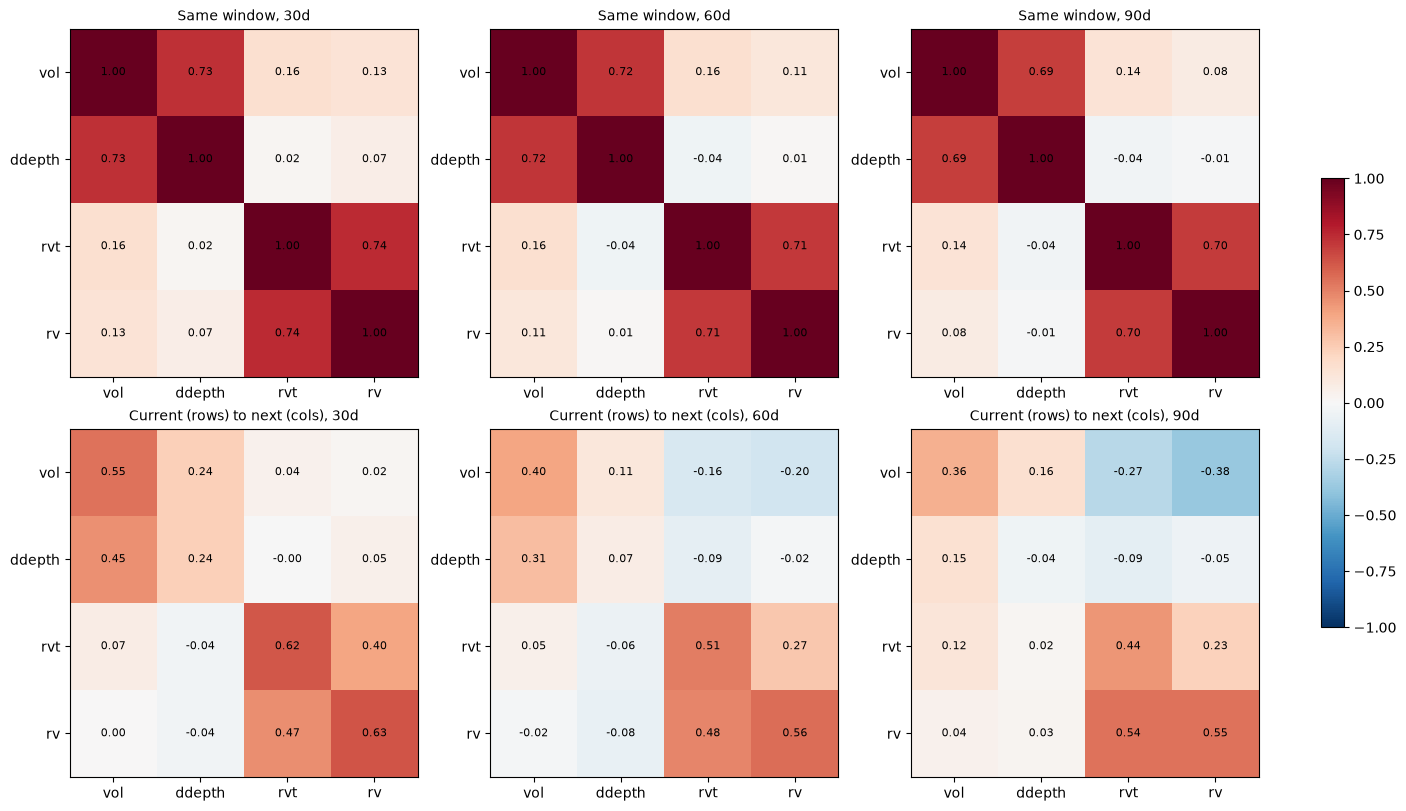

In [36]:
import matplotlib.pyplot as plt

W = [30, 60, 90]
base = ['vol', 'ddepth', 'rvt', 'rv']

# Next-window versions (days t+1 to t+w, no overlap with the current window)
for w in W:
    for v in base:
        m[f'{v}_fwd_{w}'] = m[f'{v}_{w}'].shift(-w)

print(m[[f'vol_fwd_{w}' for w in W]].isna().sum())     # expect 30, 60, 90

# 12a. Same-window Spearman correlations
same, fwd = {}, {}
for w in W:
    c = m[[f'{v}_{w}' for v in base]].corr(method='spearman')
    c.index = c.columns = base
    same[w] = c
    print(f'\nSame window, {w} days'); print(c.round(2))

# 12b. Current window (rows) -> next window (columns)
for w in W:
    cur = [f'{v}_{w}' for v in base]
    nxt = [f'{v}_fwd_{w}' for v in base]
    d = m[cur + nxt].dropna()
    c = d.corr(method='spearman').loc[cur, nxt]
    c.index = c.columns = base
    fwd[w] = c
    print(f'\nCurrent -> next, {w} days (n = {len(d)})'); print(c.round(2))

# 12c. Partial Spearman: does volume add information about the next window
#      beyond the current level of the same variable?
def partial_spearman(d, x, y, z):
    r = d[[x, y, z]].rank()
    rxy, rxz, ryz = r[x].corr(r[y]), r[x].corr(r[z]), r[y].corr(r[z])
    return (rxy - rxz * ryz) / np.sqrt((1 - rxz**2) * (1 - ryz**2))

rows = []
for w in W:
    d = m[[f'{v}_{w}' for v in base] + [f'{v}_fwd_{w}' for v in base]].dropna()
    for pred in ['rvt', 'rv']:
        rows.append({
            'window': w, 'volume': pred,
            'next vol, ctrl current vol':
                partial_spearman(d, f'{pred}_{w}', f'vol_fwd_{w}', f'vol_{w}'),
            'next ddepth, ctrl current ddepth':
                partial_spearman(d, f'{pred}_{w}', f'ddepth_fwd_{w}', f'ddepth_{w}')})
print(pd.DataFrame(rows).round(2))

# 12d. Heatmaps
fig, axes = plt.subplots(2, 3, figsize=(14, 8), constrained_layout=True)   # <-- changed
for j, w in enumerate(W):
    for i, (mat, name) in enumerate([(same[w], 'Same window'),
                                     (fwd[w], 'Current (rows) to next (cols)')]):
        ax = axes[i, j]
        im = ax.imshow(mat.values, vmin=-1, vmax=1, cmap='RdBu_r')
        ax.set_xticks(range(4)); ax.set_yticks(range(4))
        ax.set_xticklabels(base); ax.set_yticklabels(base)
        for a in range(4):
            for b in range(4):
                ax.text(b, a, f'{mat.values[a, b]:.2f}', ha='center', va='center', fontsize=8)
        ax.set_title(f'{name}, {w}d', fontsize=10)
fig.colorbar(im, ax=axes, shrink=0.6)                                       # <-- changed
plt.savefig('heatmaps_30_60_90.png', dpi=150, bbox_inches='tight')
plt.show()

In [37]:
#Day - 13 (Robustness checks).

In [38]:
#13a. Does the story survive sub-samples?
W = [30, 60, 90]
idx = m.index[m['date'] == '2017-07-10'][0]

variants = {
    'all rows':               lambda w: m,
    'excluding 2020':         lambda w: m[m['date'].dt.year != 2020],
    'excl. 10-Jul-2017 span': lambda w: m.drop(index=range(idx, idx + 90)),
    'non-overlapping':        lambda w: m.iloc[::w],
}

rows = []
for name, f in variants.items():
    for w in W:
        d = f(w)
        c = d[[f'vol_{w}', f'ddepth_{w}', f'rvt_{w}', f'rv_{w}']].corr(method='spearman')
        rows.append({'variant': name, 'window': w, 'n': len(d),
                     'vol~ddepth': c.loc[f'vol_{w}', f'ddepth_{w}'],
                     'vol~rvt':    c.loc[f'vol_{w}', f'rvt_{w}'],
                     'vol~rv':     c.loc[f'vol_{w}', f'rv_{w}'],
                     'ddepth~rvt': c.loc[f'ddepth_{w}', f'rvt_{w}']})
rob = pd.DataFrame(rows)
print(rob.round(2).to_string(index=False))
rob.to_csv('robustness_correlations.csv', index=False)

               variant  window    n  vol~ddepth  vol~rvt  vol~rv  ddepth~rvt
              all rows      30 2216        0.73     0.16    0.13        0.02
              all rows      60 2216        0.72     0.16    0.11       -0.04
              all rows      90 2216        0.69     0.14    0.08       -0.04
        excluding 2020      30 1965        0.73     0.00    0.10       -0.07
        excluding 2020      60 1965        0.71    -0.02    0.07       -0.16
        excluding 2020      90 1965        0.68    -0.06   -0.00       -0.18
excl. 10-Jul-2017 span      30 2126        0.74     0.18    0.13        0.03
excl. 10-Jul-2017 span      60 2126        0.70     0.17    0.11       -0.03
excl. 10-Jul-2017 span      90 2126        0.66     0.15    0.08       -0.03
       non-overlapping      30   74        0.74     0.11    0.11        0.02
       non-overlapping      60   37        0.73     0.07    0.04       -0.11
       non-overlapping      90   25        0.71     0.19    0.16       -0.13

In [39]:
#13b. Look-ahead check.
def expanding_regime(s, minp=250):
    lo = s.expanding(min_periods=minp).quantile(0.25)
    hi = s.expanding(min_periods=minp).quantile(0.75)
    r = pd.Series(np.where(s <= lo, 'low', np.where(s >= hi, 'high', 'mid')), index=s.index)
    return r.where(lo.notna())

for w in W:
    r = expanding_regime(m[f'vol_{w}'])
    g = m.groupby(r)[[f'ddepth_{w}', f'rvt_{w}', f'rv_{w}']].mean()
    print(f'\nWindow {w}: n by regime =', r.value_counts().to_dict())
    print('high minus low:', (g.loc['high'] - g.loc['low']).round(3).to_dict())


Window 30: n by regime = {'mid': 909, 'high': 667, 'low': 391}
high minus low: {'ddepth_30': 0.055, 'rvt_30': 0.152, 'rv_30': 0.181}

Window 60: n by regime = {'mid': 868, 'high': 793, 'low': 306}
high minus low: {'ddepth_60': 0.069, 'rvt_60': 0.141, 'rv_60': 0.181}

Window 90: n by regime = {'mid': 829, 'high': 828, 'low': 310}
high minus low: {'ddepth_90': 0.078, 'rvt_90': 0.103, 'rv_90': 0.133}


In [40]:
#13c. Does the volume baseline drive the odd negative link?
src = pd.read_csv('Nifty_10y_clean.csv', parse_dates=['date'])[['date', 'turnover_cr']]

def with_baseline(base):
    t = src['turnover_cr']
    out = src[['date']].copy()
    for w in W:
        out[f'rvt_{w}'] = t.rolling(w, min_periods=w).mean() / t.rolling(base, min_periods=base).mean()
        out[f'rvt_fwd_{w}'] = out[f'rvt_{w}'].shift(-w)
    return out

rows = []
for base in [120, 250, 500]:
    x = m[['date'] + [f'vol_{w}' for w in W]].merge(with_baseline(base), on='date')
    for w in W:
        d = x[[f'vol_{w}', f'rvt_{w}', f'rvt_fwd_{w}']].dropna()
        rows.append({'baseline': base, 'window': w, 'n': len(d),
                     'vol~rvt (same)': d[f'vol_{w}'].corr(d[f'rvt_{w}'], method='spearman'),
                     'vol~rvt (next)': d[f'vol_{w}'].corr(d[f'rvt_fwd_{w}'], method='spearman')})
print(pd.DataFrame(rows).round(2).to_string(index=False))

 baseline  window    n  vol~rvt (same)  vol~rvt (next)
      120      30 2186            0.20           -0.02
      120      60 2156            0.19           -0.34
      120      90 2126            0.09           -0.34
      250      30 2186            0.16            0.04
      250      60 2156            0.13           -0.16
      250      90 2126            0.10           -0.27
      500      30 1936            0.30            0.17
      500      60 1906            0.31           -0.02
      500      90 1876            0.30           -0.09


In [41]:
#Day - 14 (#Visuals : Scatter plots with trend lines, box plots by regime, heatmaps, and rolling-line overlays).

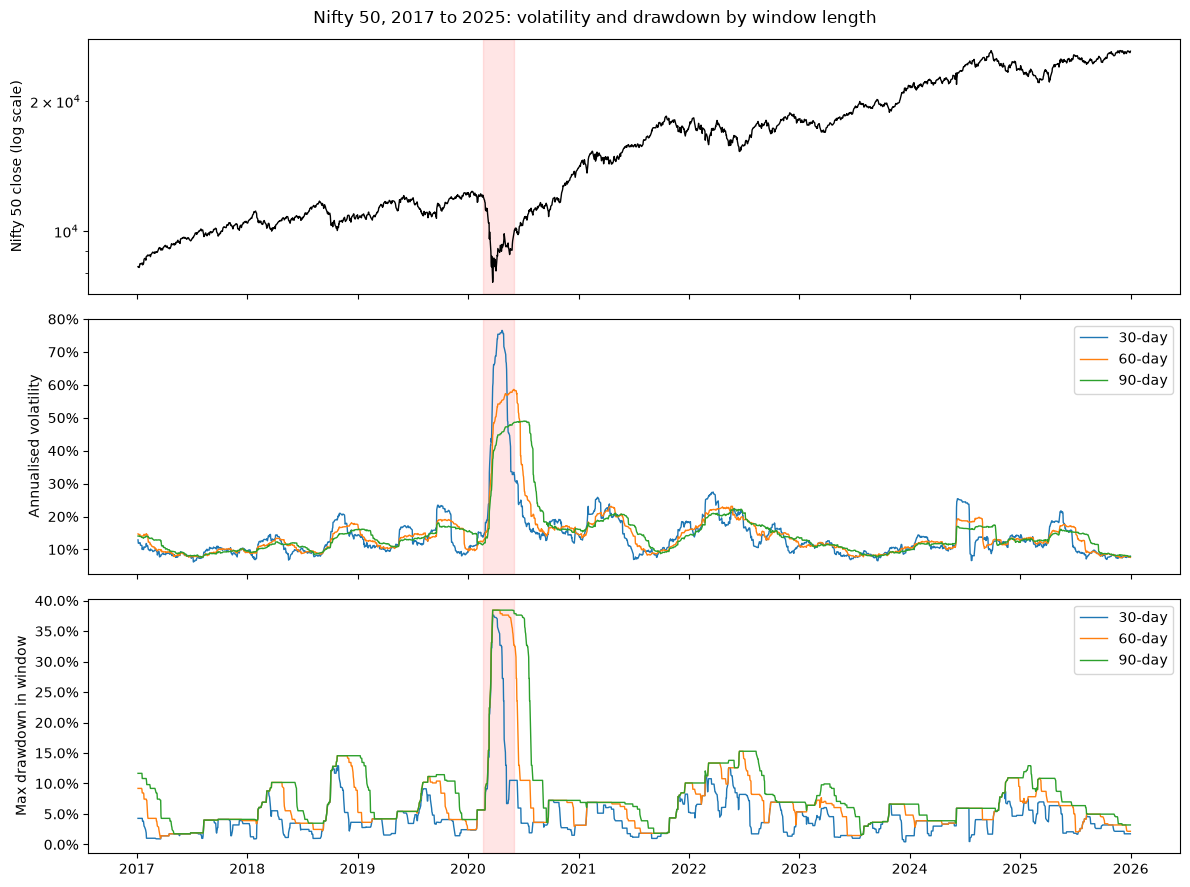

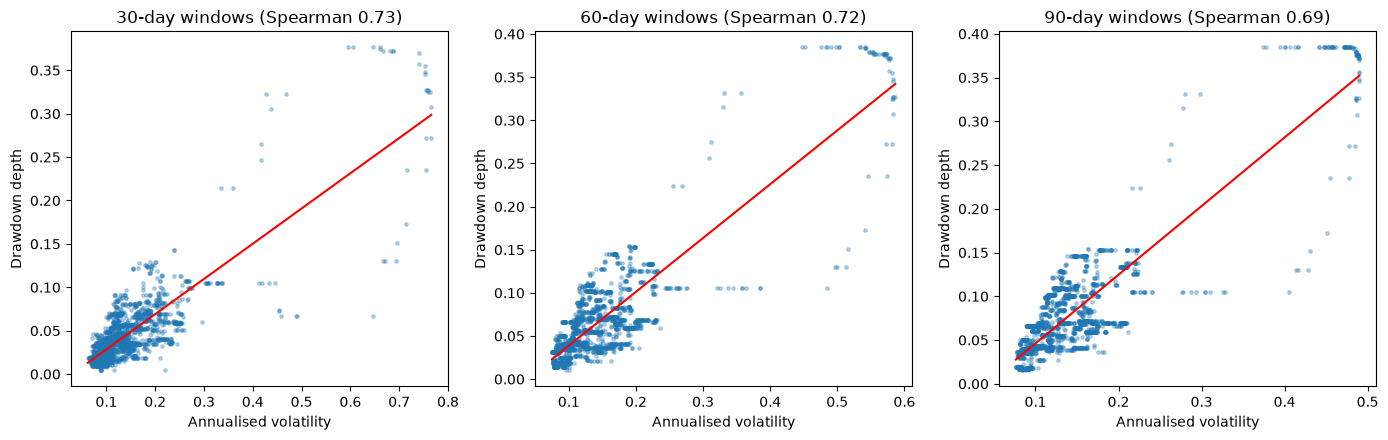

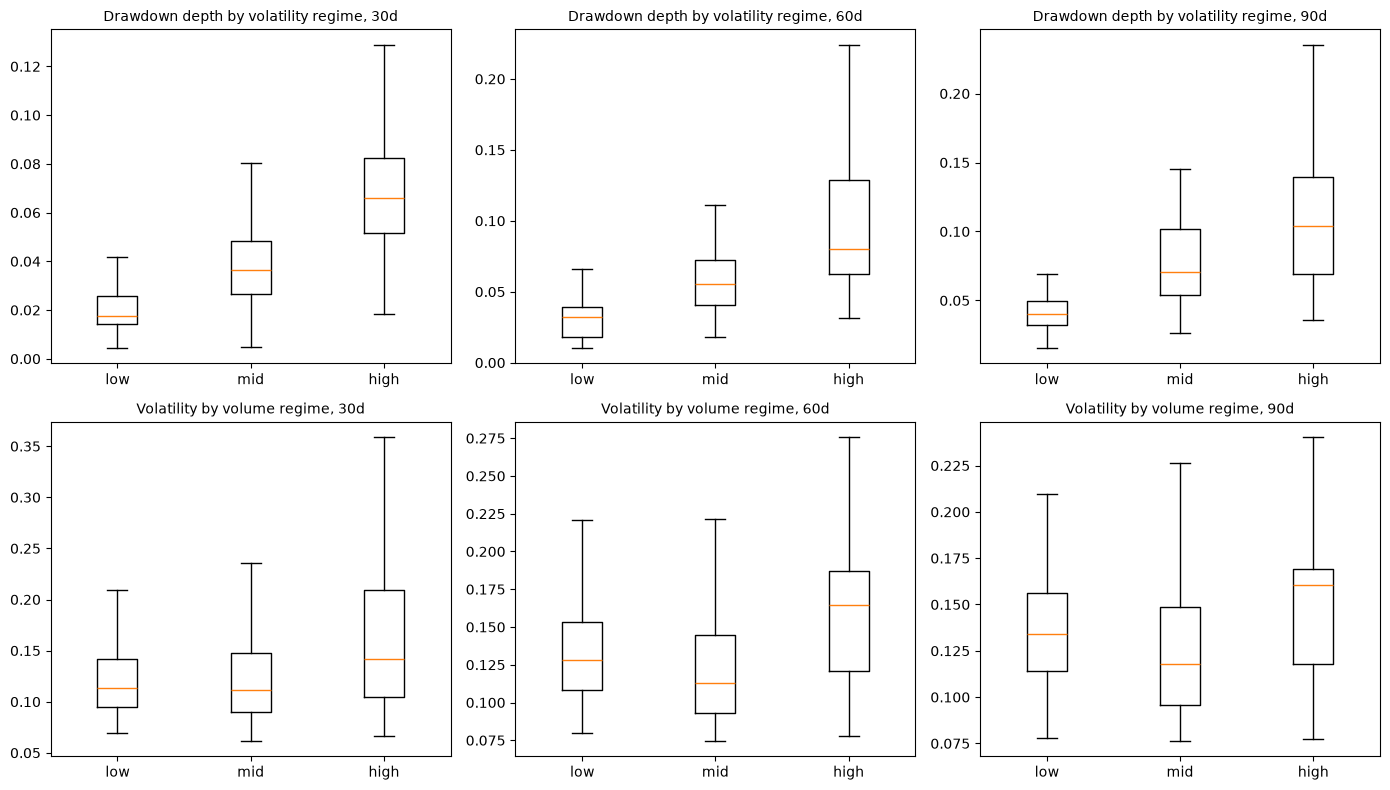

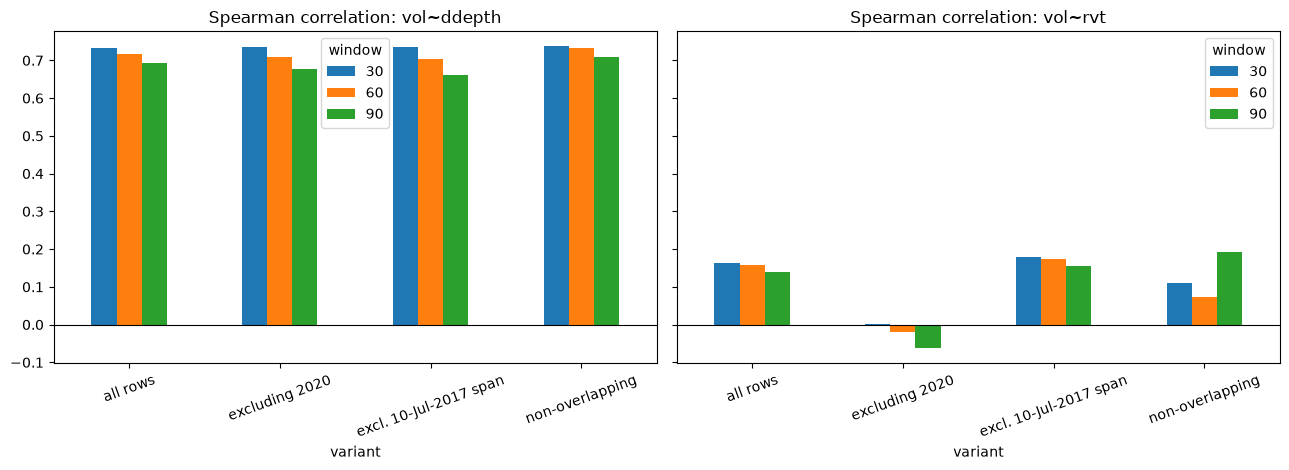

In [42]:
#Visuals.
import matplotlib.pyplot as plt
from matplotlib.ticker import PercentFormatter

W = [30, 60, 90]
order = ['low', 'mid', 'high']

# Figure 1: price, volatility and drawdown over time (COVID crash shaded)
fig, ax = plt.subplots(3, 1, figsize=(12, 9), sharex=True)
ax[0].plot(m['date'], m['close'], color='black', lw=1)
ax[0].set_yscale('log'); ax[0].set_ylabel('Nifty 50 close (log scale)')
for w, c in zip(W, ['tab:blue', 'tab:orange', 'tab:green']):
    ax[1].plot(m['date'], m[f'vol_{w}'], label=f'{w}-day', color=c, lw=1)
    ax[2].plot(m['date'], m[f'ddepth_{w}'], label=f'{w}-day', color=c, lw=1)
ax[1].set_ylabel('Annualised volatility'); ax[1].yaxis.set_major_formatter(PercentFormatter(1.0))
ax[2].set_ylabel('Max drawdown in window'); ax[2].yaxis.set_major_formatter(PercentFormatter(1.0))
ax[1].legend(); ax[2].legend()
for a in ax:
    a.axvspan(pd.Timestamp('2020-02-20'), pd.Timestamp('2020-05-31'), color='red', alpha=0.1)
fig.suptitle('Nifty 50, 2017 to 2025: volatility and drawdown by window length')
plt.tight_layout(); plt.savefig('fig1_timeseries.png', dpi=150); plt.show()

# Figure 2: volatility vs drawdown depth, with trend line
fig, axes = plt.subplots(1, 3, figsize=(14, 4.5))
for a, w in zip(axes, W):
    x, y = m[f'vol_{w}'], m[f'ddepth_{w}']
    a.scatter(x, y, s=6, alpha=0.3)
    k, b = np.polyfit(x, y, 1)
    xs = np.linspace(x.min(), x.max(), 50)
    a.plot(xs, k * xs + b, color='red', lw=1.5)
    a.set_title(f'{w}-day windows (Spearman {x.corr(y, method="spearman"):.2f})')
    a.set_xlabel('Annualised volatility'); a.set_ylabel('Drawdown depth')
plt.tight_layout(); plt.savefig('fig2_vol_vs_drawdown.png', dpi=150); plt.show()

# Figure 3: distributions by regime (outliers hidden for readability)
fig, axes = plt.subplots(2, 3, figsize=(14, 8))
for j, w in enumerate(W):
    for i, (reg, val, ttl) in enumerate([
            (f'vol_reg_{w}', f'ddepth_{w}', 'Drawdown depth by volatility regime'),
            (f'vlm_reg_{w}', f'vol_{w}',    'Volatility by volume regime')]):
        data = [m.loc[m[reg] == r, val] for r in order]
        axes[i, j].boxplot(data, showfliers=False)
        axes[i, j].set_xticklabels(order)
        axes[i, j].set_title(f'{ttl}, {w}d', fontsize=10)
plt.tight_layout(); plt.savefig('fig3_boxplots.png', dpi=150); plt.show()

# Figure 4: robustness of the two headline relationships
order_v = ['all rows', 'excluding 2020', 'excl. 10-Jul-2017 span', 'non-overlapping']
fig, axes = plt.subplots(1, 2, figsize=(13, 4.8), sharey=True)
for a, col in zip(axes, ['vol~ddepth', 'vol~rvt']):
    (rob.pivot_table(index='variant', columns='window', values=col)
        .loc[order_v].plot.bar(ax=a, rot=20))
    a.set_title(f'Spearman correlation: {col}'); a.axhline(0, color='black', lw=0.8)
plt.tight_layout(); plt.savefig('fig4_robustness.png', dpi=150); plt.show()